# 🩸 Proje 2 · Bölüm 4 — Açıklanabilirlik, adalet ve mobil uygulama
**Seviye: İleri**

Klinikte bir model kullanılacaksa üç soru sorulur:
1. **Bu hasta için neden bu sonucu verdi?** (bireysel açıklama)
2. **Herkes için eşit derecede iyi çalışıyor mu?** (alt grup analizi / adalet)
3. **Hastanın elinde nasıl çalışacak?** (dağıtım / mobil uygulama)

In [1]:
# Google Colab'da çalışıyorsanız proje klasörünü (zip) yükleyin
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 02_Diyabet.zip dosyasını seçin"); files.upload()
    !unzip -q -o 02_Diyabet.zip
    %cd 02_Diyabet
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/02_Diyabet


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, json, warnings
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", font_scale=0.9)
OZELLIKLER = ["Gebelik", "Glukoz", "KanBasinci", "DeriKalinligi", "Insulin", "VKI", "SoygecmisSkoru", "Yas"]

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve

veri = pd.read_csv("veri/diyabet_temiz.csv")
bol = pd.read_json("islenmis/bolunme.json", typ="series")
egt, tst = veri.loc[bol["egitim"]], veri.loc[bol["test"]]
X_egt, y_egt, X_tst, y_tst = egt[OZELLIKLER], egt.Diyabet.values, tst[OZELLIKLER], tst.Diyabet.values
model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_egt, y_egt)
p_tst = model.predict_proba(X_tst)[:, 1]
print("Test AUC:", round(roc_auc_score(y_tst, p_tst), 3))

Test AUC: 0.824


## 1. Genel önem: permütasyon yöntemi
Bir değişkenin değerlerini hastalar arasında **rastgele karıştırırız**. Model başarısı ne kadar düşerse, o değişken o kadar önemlidir. (Her modelde kullanılabilen, modelden bağımsız bir yöntem.)

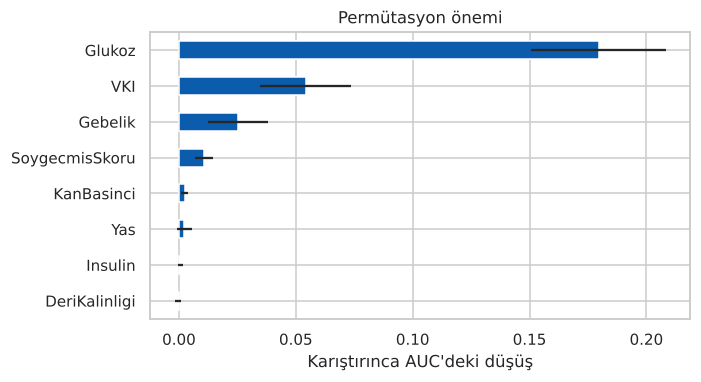

In [3]:
pi = permutation_importance(model, X_tst, y_tst, scoring="roc_auc", n_repeats=50, random_state=0)
onem = pd.DataFrame({"ort": pi.importances_mean, "std": pi.importances_std}, index=OZELLIKLER).sort_values("ort")
onem["ort"].plot.barh(xerr=onem["std"], color="#0b5cad", figsize=(6.5, 3.6))
plt.xlabel("Karıştırınca AUC'deki düşüş"); plt.title("Permütasyon önemi"); plt.tight_layout(); plt.show()

## 2. Bireysel açıklama: "Bu hastanın riski neden yüksek?"
Lojistik regresyonda her değişkenin katkısı = **katsayı × (standartlaştırılmış değer)**. Ortalama bir kişiye göre riski hangi değişkenin ne kadar artırdığını/azalttığını gösterir. (SHAP yöntemi doğrusal modellerde tam olarak buna karşılık gelir.)

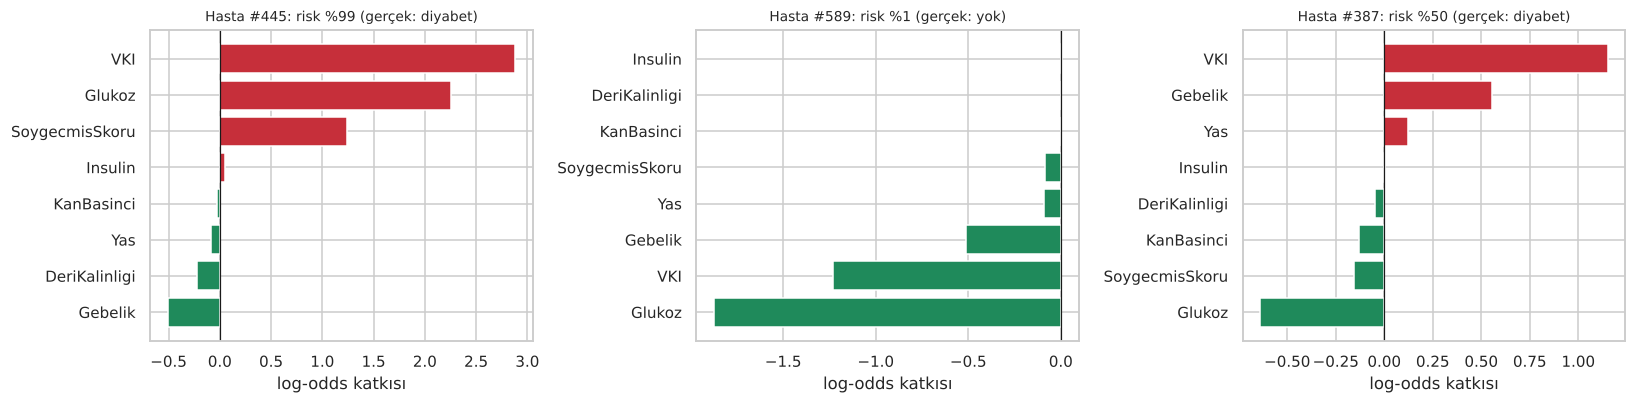

,Gebelik,Glukoz,KanBasinci,DeriKalinligi,Insulin,VKI,SoygecmisSkoru,Yas,Diyabet
445,0,180.0,78.0,63.0,14.0,59.4,2.420,25,1
589,0,73.0,NaN,NaN,NaN,21.1,0.342,25,0
387,8,105.0,100.0,36.0,NaN,43.3,0.239,45,1


In [4]:
imp, olc, lr = model[0], model[1], model[2]
def katki(satir):
    z = olc.transform(imp.transform(satir[OZELLIKLER].to_frame().T))[0]
    return pd.Series(lr.coef_[0] * z, index=OZELLIKLER)

ornek_idx = [tst.index[np.argmax(p_tst)], tst.index[np.argmin(p_tst)], tst.index[np.argmin(np.abs(p_tst - 0.5))]]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for a, i in zip(axes, ornek_idx):
    k = katki(veri.loc[i]).sort_values()
    p = model.predict_proba(veri.loc[[i], OZELLIKLER])[0, 1]
    a.barh(k.index, k.values, color=np.where(k > 0, "#c62f3a", "#1f8a5b")); a.axvline(0, c="k", lw=.8)
    a.set_title(f"Hasta #{i}: risk %{100*p:.0f} (gerçek: {'diyabet' if veri.Diyabet[i] else 'yok'})", fontsize=9)
    a.set_xlabel("log-odds katkısı")
plt.tight_layout(); plt.show()
veri.loc[ornek_idx, OZELLIKLER + ["Diyabet"]]

## 3. Alt grup analizi: model herkes için aynı derecede iyi mi?
Bir model bütünde iyi, ama belli bir grupta (ör. gençlerde) kötü olabilir. Bu, **algoritmik yanlılık (bias)** sorunudur.

In [5]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
# Tüm veride çapraz-doğrulanmış tahminler (alt gruplarda yeterli sayı olsun diye)
p_tum = cross_val_predict(model, veri[OZELLIKLER], veri.Diyabet, cv=StratifiedKFold(10, shuffle=True, random_state=0), method="predict_proba")[:, 1]
gruplar = {
    "Yaş < 30": veri.Yas < 30, "Yaş 30-49": (veri.Yas >= 30) & (veri.Yas < 50), "Yaş ≥ 50": veri.Yas >= 50,
    "VKİ < 30": veri.VKI < 30, "VKİ ≥ 30 (obez)": veri.VKI >= 30,
    "Hiç gebelik yok": veri.Gebelik == 0, "Gebelik ≥ 1": veri.Gebelik >= 1,
}
satir = []
for ad, m in gruplar.items():
    yy, pp = veri.Diyabet[m].values, p_tum[m.values]
    t = pp >= 0.5
    satir.append({"Alt grup": ad, "Kişi": int(m.sum()), "Diyabet %": 100 * yy.mean(), "AUC": roc_auc_score(yy, pp),
                  "Duyarlılık": (t & (yy == 1)).sum() / max((yy == 1).sum(), 1), "Ort. tahmin %": 100 * pp.mean()})
pd.DataFrame(satir).set_index("Alt grup").round(2)

,Kişi,Diyabet %,AUC,Duyarlılık,Ort. tahmin %
Alt grup,,,,,
Yaş < 30,396,21.21,0.85,0.44,24.17
Yaş 30-49,283,49.82,0.78,0.59,44.12
Yaş ≥ 50,89,48.31,0.74,0.72,53.82
VKİ < 30,285,16.49,0.83,0.30,19.80
VKİ ≥ 30 (obez),472,46.40,0.80,0.63,44.38
Hiç gebelik yok,111,34.23,0.83,0.53,31.45
Gebelik ≥ 1,657,35.01,0.84,0.57,35.55


**Yorum:** Gençlerde ve obez olmayanlarda diyabet daha nadir → aynı eşikte **duyarlılık düşer**. Ayrıca bu model **yalnızca Pima kadınlarıyla** eğitildi; erkeklere ya da Türk toplumuna doğrudan uygulanması bilimsel olarak doğru değildir. Bu sınırlılıklar uygulamada açıkça yazılmalıdır.

## 4. Mobil uygulama için dışa aktarma
Lojistik regresyonun tüm "bilgisi" birkaç sayıdan ibarettir: doldurma medyanları, ortalamalar, standart sapmalar, 8 katsayı ve 1 sabit terim. Bunları JSON olarak kaydediyoruz; uygulama aynı formülü telefonda uygular.

**Karar eşiği:** Tarama amaçlı bir araç olduğu için, eğitim setinde **duyarlılığı ≥ %80** tutan en yüksek eşiği seçiyoruz.

In [6]:
p_egt = model.predict_proba(X_egt)[:, 1]
fpr, tpr, e = roc_curve(y_egt, p_egt)
esik = float(e[np.argmax(tpr >= 0.80)])
t = p_tst >= esik
print(f"Seçilen eşik: {esik:.3f} → test setinde duyarlılık {(t & (y_tst==1)).sum()/(y_tst==1).sum():.2f}, "
      f"özgüllük {(~t & (y_tst==0)).sum()/(y_tst==0).sum():.2f}")

disa = {
    "ozellikler": OZELLIKLER,
    "medyan": imp.statistics_.round(6).tolist(),
    "ortalama": olc.mean_.round(6).tolist(), "std": olc.scale_.round(6).tolist(),
    "katsayi": lr.coef_[0].round(6).tolist(), "sabit": round(float(lr.intercept_[0]), 6),
    "esik": round(esik, 4), "test_auc": round(float(roc_auc_score(y_tst, p_tst)), 3),
    "veri": "Pima Indians Diabetes (NIDDK), 768 kadın, 21+ yaş", "egitim_n": int(len(X_egt)),
}
os.makedirs("mobil/www", exist_ok=True)
json.dump(disa, open("model/diyabet_lr.json", "w"), ensure_ascii=False, indent=1)
open("mobil/www/model.js", "w").write("window.DIYABET_MODEL = " + json.dumps(disa, ensure_ascii=False) + ";\n")
disa

Seçilen eşik: 0.285 → test setinde duyarlılık 0.78, özgüllük 0.69


{'ozellikler': ['Gebelik',
  'Glukoz',
  'KanBasinci',
  'DeriKalinligi',
  'Insulin',
  'VKI',
  'SoygecmisSkoru',
  'Yas'],
 'medyan': [3.0, 117.0, 72.0, 29.0, 125.0, 32.4, 0.384, 30.0],
 'ortalama': [3.831597,
  121.579861,
  72.045139,
  29.081597,
  137.144097,
  32.570833,
  0.4802,
  33.536458],
 'std': [3.309987,
  30.096902,
  12.250909,
  8.818498,
  78.634274,
  6.735678,
  0.332899,
  11.868436],
 'katsayi': [0.440424,
  1.161356,
  -0.057382,
  -0.058248,
  -0.03069,
  0.723911,
  0.212235,
  0.126012],
 'sabit': -0.864148,
 'esik': 0.2854,
 'test_auc': 0.824,
 'veri': 'Pima Indians Diabetes (NIDDK), 768 kadın, 21+ yaş',
 'egitim_n': 576}

In [7]:
# Doğrulama: telefondaki JavaScript formülü Python ile aynı sonucu veriyor mu?
import subprocess, shutil
if shutil.which("node"):
    girdiler = X_tst.replace({np.nan: None}).values.tolist()
    betik = """
    global.window = global; const fs = require('fs');
    eval(fs.readFileSync('mobil/www/model.js','utf8')); eval(fs.readFileSync('mobil/www/risk.js','utf8'));
    const g = JSON.parse(fs.readFileSync(0,'utf8'));
    console.log(JSON.stringify(g.map(r => DiyabetRisk.hesapla(Object.fromEntries(DIYABET_MODEL.ozellikler.map((k,i)=>[k,r[i]]))).risk)));"""
    js = np.array(json.loads(subprocess.run(["node", "-e", betik], input=json.dumps(girdiler), capture_output=True, text=True, check=True).stdout))
    print(f"{len(js)} test hastası | en büyük fark: {np.abs(js - p_tst).max():.1e}")

192 test hastası | en büyük fark: 5.6e-07


## ✅ Sonuç
`DiyabetRisk.apk` uygulaması:
* Kullanıcı değerlerini girer (bilinmeyenler boş bırakılabilir → eğitim medyanı kullanılır),
* **Risk yüzdesi**, risk kategorisi ve **her değişkenin katkısı** gösterilir,
* "**Ya şöyle olsaydı?**" kaydırıcılarıyla (ör. kilo verme) riskin nasıl değiştiği anında görülür.

💡 **Araştırma fikirleri**
* Hasta eğitiminde "ya şöyle olsaydı" türü **etkileşimli risk iletişimi** araçlarının yaşam tarzı değişikliğine etkisi (randomize çalışma).
* Model açıklamalarının hekim güvenine ve karar değişikliğine etkisi.
* Aynı modelin farklı toplumlarda **yeniden kalibrasyonu** (recalibration) — Türkiye verisiyle.